In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
datos = pd.read_csv("cafe.csv")

In [6]:
datos.head()

,temperatura_c,cafes_vendidos
0,29,77
1,22,95
2,15,115
3,33,54
4,18,109


In [7]:
datos.describe()

,temperatura_c,cafes_vendidos
count,90.000000,90.000000
mean,24.044444,88.855556
std,5.568594,20.215447
min,15.000000,47.000000
25%,19.000000,73.250000
50%,23.500000,90.500000
75%,29.000000,103.000000
max,33.000000,131.000000


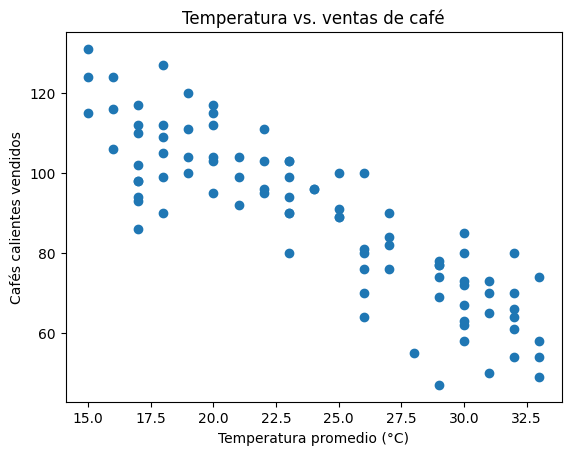

In [9]:
plt.scatter(
    datos["temperatura_c"],
    datos["cafes_vendidos"]
)
plt.xlabel("Temperatura promedio (°C)")
plt.ylabel("Cafés calientes vendidos")
plt.title("Temperatura vs. ventas de café")
plt.show()

In [10]:
from sklearn.linear_model import LinearRegression

X = datos[["temperatura_c"]]
y = datos["cafes_vendidos"]

In [11]:
modelo = LinearRegression()

In [12]:
modelo.fit(X,y)

LinearRegression()

In [13]:
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_

print("La pendiente es:", pendiente)
print("El intercepto es:", intercepto)

La pendiente es: -3.1561533754187074
El intercepto es: 164.74351004895647


In [14]:
manana = pd.DataFrame({
    "temperatura_c":[20]
})

prediccion = modelo.predict(manana)

print("Mañana se venderan", prediccion, "cafés")

Mañana se venderan [101.62044254] cafés


In [16]:
pronostico = pd.DataFrame({
    "temperatura_c":[16,24,32]
})

pronostico["ventas_estimadas"] = modelo.predict(
    pronostico[["temperatura_c"]]
).round().astype(int)

pronostico

,temperatura_c,ventas_estimadas
0,16,114
1,24,89
2,32,64


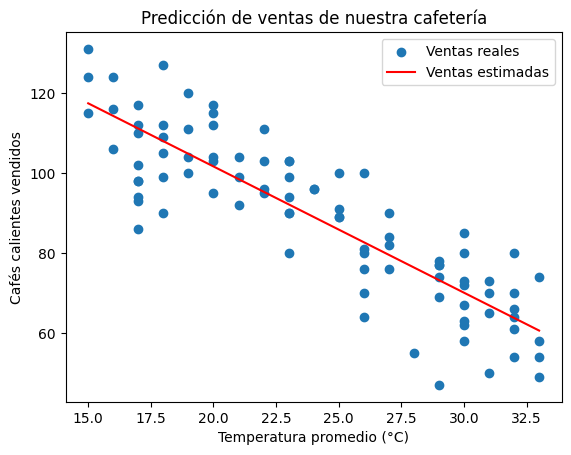

In [18]:
import numpy as np

temperaturas = np.linspace(
    datos["temperatura_c"].min(),
    datos["temperatura_c"].max(),
    100
    )

nuevas_temperaturas = pd.DataFrame({
    "temperatura_c": temperaturas
    })

ventas_estimadas = modelo.predict(nuevas_temperaturas)

plt.scatter(
    datos["temperatura_c"],
    datos["cafes_vendidos"],
    label = "Ventas reales"
    )

plt.plot(
    temperaturas,
    ventas_estimadas,
    color="red",
    label="Ventas estimadas"
)

plt.xlabel("Temperatura promedio (°C)")
plt.ylabel("Cafés calientes vendidos")
plt.title("Predicción de ventas de nuestra cafetería")
plt.legend()
plt.show()

In [20]:
cafes_estimados = 85
leche_por_cafe = 200

litros_leche = (
    cafes_estimados * leche_por_cafe / 1000
)

In [21]:
print("Leche necesaria:", litros_leche, "litros")

Leche necesaria: 17.0 litros


In [24]:
from sklearn.metrics import mean_absolute_error
predicciones = modelo.predict(X)
error = mean_absolute_error(y, predicciones)
print("Error promedio:", error, "cafés" )

Error promedio: 7.833796773454723 cafés
